In [ ]:
!pip install -q kagglehub openpyxl wordcloud matplotlib seaborn pandas numpy

import os
import glob
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Buat folder lokal di Colab agar rapi sesuai struktur GitHub
os.makedirs("dataset", exist_ok=True)
os.makedirs("reports/figures", exist_ok=True)

In [ ]:
# Download seluruh dataset dari Kaggle
dataset_dir = kagglehub.dataset_download("linkgish/indonesian-fact-and-hoax-political-news")
print("Lokasi folder dataset:", dataset_dir)

# Cari semua file .xlsx di dalam folder (fokus ke file versi 'cleaned')
all_xlsx = glob.glob(os.path.join(dataset_dir, "**", "*.xlsx"), recursive=True)
cleaned_files = [f for f in all_xlsx if "cleaned" in os.path.basename(f).lower()]

# Fallback jika penamaan file berbeda
target_files = cleaned_files if len(cleaned_files) > 0 else all_xlsx

print(f"\nDitemukan {len(target_files)} file target:")
for f in sorted(target_files):
    size_mb = os.path.getsize(f) / (1024 * 1024)
    print(f" - {os.path.basename(f)} ({size_mb:.2f} MB)")

Using Colab cache for faster access to the 'indonesian-fact-and-hoax-political-news' dataset.
Lokasi folder dataset: /kaggle/input/indonesian-fact-and-hoax-political-news

Ditemukan 4 file target:
 - dataset_cnn_10k_cleaned.xlsx (9.02 MB)
 - dataset_kompas_4k_cleaned.xlsx (4.35 MB)
 - dataset_tempo_6k_cleaned.xlsx (6.30 MB)
 - dataset_turnbackhoax_10_cleaned.xlsx (12.34 MB)


In [ ]:
dfs = []

for file_path in sorted(target_files):
    fname = os.path.basename(file_path).lower()
    temp = pd.read_excel(file_path)
    print(f"\nFile: {fname} | Shape: {temp.shape}")
    print(f"Kolom asli: {temp.columns.tolist()}")

    # Deteksi otomatis kolom judul, teks/narasi, dan label agar tidak error
    cols_lower = {c.lower(): c for c in temp.columns}

    # Cari kolom judul
    title_col = next((cols_lower[k] for k in ['title', 'judul'] if k in cols_lower), None)
    # Cari kolom teks utama (prioritaskan FullText / Clean Narasi / Narasi / text_new)
    text_col = next((cols_lower[k] for k in ['text_new', 'clean narasi', 'fulltext', 'narasi', 'isi', 'text'] if k in cols_lower), None)
    # Cari kolom label bawaan (hoax)
    label_col = next((cols_lower[k] for k in ['hoax', 'label'] if k in cols_lower), None)

    std_df = pd.DataFrame()
    std_df['source'] = fname.replace('dataset_', '').replace('_cleaned.xlsx', '').replace('.xlsx', '')
    std_df['title'] = temp[title_col].astype(str) if title_col else ""
    std_df['body'] = temp[text_col].astype(str) if text_col else ""

    # Tentukan label: 1 = Hoaks (TurnBackHoax), 0 = Fakta (CNN, Kompas, Tempo)
    if label_col is not None:
        std_df['label'] = pd.to_numeric(temp[label_col], errors='coerce')
    else:
        std_df['label'] = 1 if 'turnbackhoax' in fname else 0

    # Pastikan label sesuai sumber jika ada NaN pada kolom label
    std_df['label'] = std_df['label'].fillna(1 if 'turnbackhoax' in fname else 0).astype(int)
    dfs.append(std_df)

df = pd.concat(dfs, ignore_index=True)

# Gabungkan judul + isi teks menjadi satu kolom mentah untuk analisis
df['raw_text'] = (df['title'].fillna('') + ' ' + df['body'].fillna('')).str.strip()
df['word_count'] = df['raw_text'].apply(lambda x: len(str(x).split()))

print("\n" + "="*50)
print(f"TOTAL GABUNGAN DATASET -> Baris (N): {df.shape[0]}, Kolom (D): {df.shape[1]}")
print("="*50)
display(df.head())


File: dataset_cnn_10k_cleaned.xlsx | Shape: (9630, 9)
Kolom asli: ['Unnamed: 0', 'Title', 'Timestamp', 'FullText', 'Tags', 'Author', 'Url', 'text_new', 'hoax']

File: dataset_kompas_4k_cleaned.xlsx | Shape: (4750, 9)
Kolom asli: ['Unnamed: 0', 'Title', 'Timestamp', 'FullText', 'Tags', 'Author', 'Url', 'text_new', 'hoax']

File: dataset_tempo_6k_cleaned.xlsx | Shape: (6592, 9)
Kolom asli: ['Unnamed: 0', 'Title', 'Timestamp', 'FullText', 'Tags', 'Author', 'Url', 'text_new', 'hoax']

File: dataset_turnbackhoax_10_cleaned.xlsx | Shape: (10381, 11)
Kolom asli: ['Unnamed: 0', 'Title', 'Timestamp', 'FullText', 'Tags', 'Author', 'Url', 'politik', 'Narasi', 'Clean Narasi', 'hoax']

TOTAL GABUNGAN DATASET -> Baris (N): 31353, Kolom (D): 6


,source,title,body,label,raw_text,word_count
0,NaN,Anies di Milad BKMT: Pengajian Menghasilkan Ib...,Anies di Milad BKMT: Pengajian Menghasilkan Ib...,0,Anies di Milad BKMT: Pengajian Menghasilkan Ib...,271
1,NaN,Edy Soal Pilgub Sumut: Kalau yang Maju Abal-ab...,Edy Soal Pilgub Sumut: Kalau yang Maju Abal-ab...,0,Edy Soal Pilgub Sumut: Kalau yang Maju Abal-ab...,292
2,NaN,PKB Bakal Daftarkan Menaker Ida Fauziyah Jadi ...,PKB Bakal Daftarkan Menaker Ida Fauziyah Jadi ...,0,PKB Bakal Daftarkan Menaker Ida Fauziyah Jadi ...,195
3,NaN,Gede Pasek Doakan AHY Jadi Capres atau Cawapres,Gede Pasek Doakan AHY Jadi Capres atau Cawapre...,0,Gede Pasek Doakan AHY Jadi Capres atau Cawapre...,193
4,NaN,PKN Siapkan Jabatan Khusus Buat Anas Urbaningr...,PKN Siapkan Jabatan Khusus Buat Anas Urbaningr...,0,PKN Siapkan Jabatan Khusus Buat Anas Urbaningr...,210


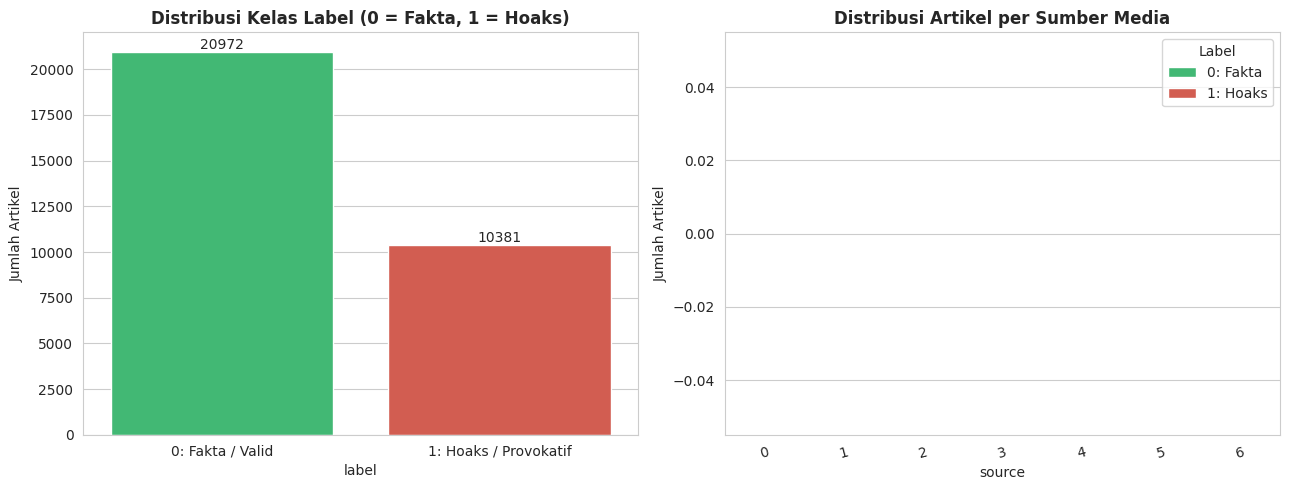

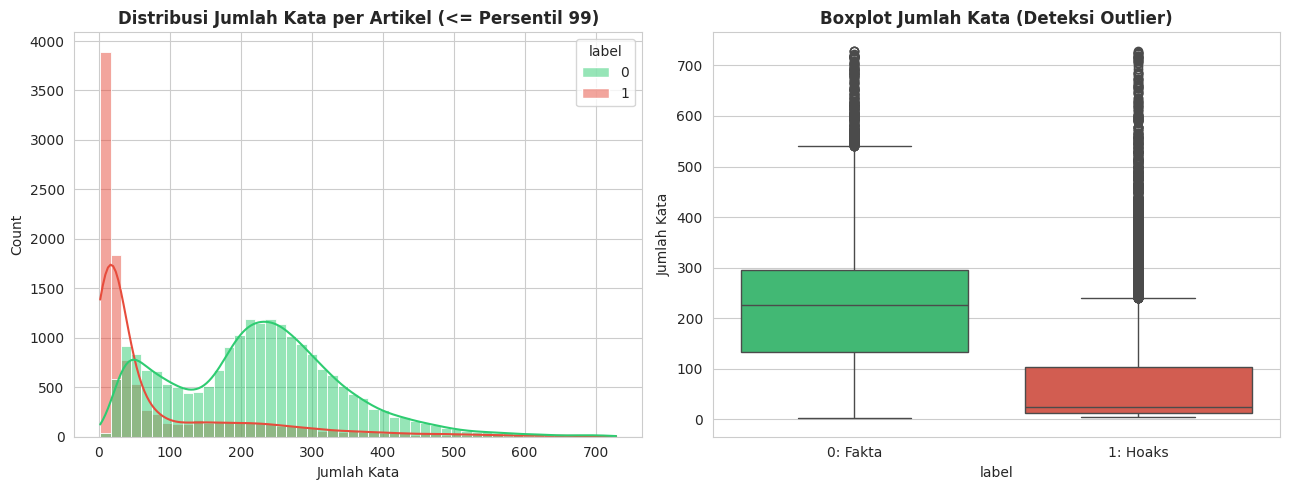

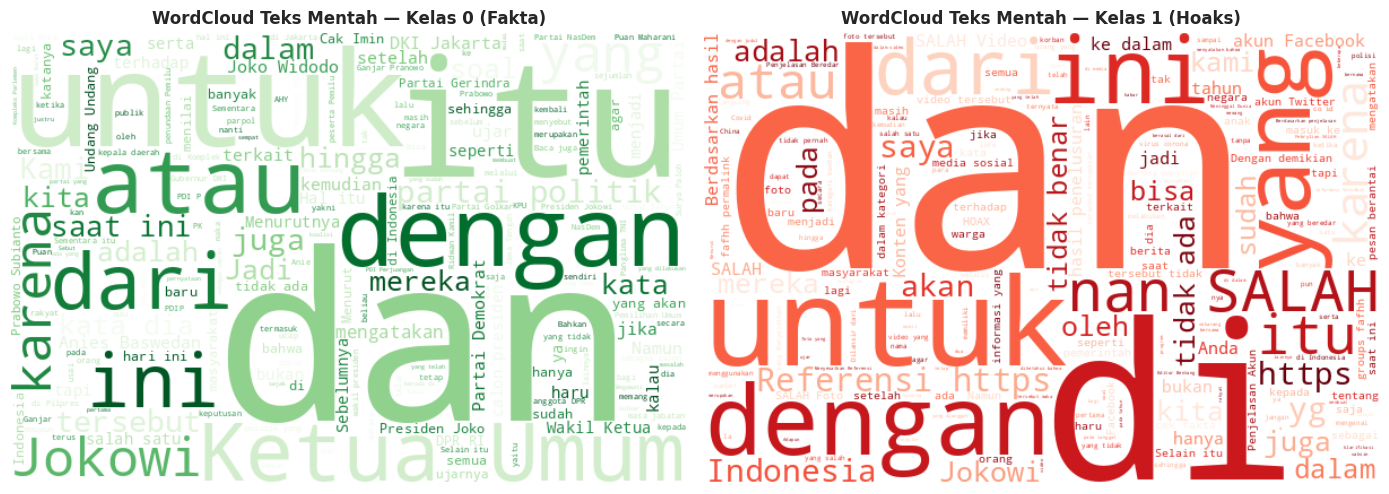

In [ ]:
sns.set_style("whitegrid")

# --- VISUALISASI 1: Distribusi Kelas & Sumber Media ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, x='label', hue='label', palette=['#2ecc71', '#e74c3c'], legend=False, ax=axes[0])
axes[0].set_title('Distribusi Kelas Label (0 = Fakta, 1 = Hoaks)', fontsize=12, fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['0: Fakta / Valid', '1: Hoaks / Provokatif'])
axes[0].set_ylabel('Jumlah Artikel')
for container in axes[0].containers:
    axes[0].bar_label(container)

sns.countplot(data=df, x='source', hue='label', palette=['#2ecc71', '#e74c3c'], ax=axes[1])
axes[1].set_title('Distribusi Artikel per Sumber Media', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Jumlah Artikel')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(title='Label', labels=['0: Fakta', '1: Hoaks'])

plt.tight_layout()
plt.savefig("reports/figures/fig1_class_distribution.png", dpi=150)
plt.show()

# --- VISUALISASI 2: Distribusi Panjang Kata & Boxplot Outlier ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Batasi sumbu X ke persentil 99 agar grafik terbaca jelas
p99 = df['word_count'].quantile(0.99)
sns.histplot(data=df[df['word_count'] <= p99], x='word_count', hue='label', bins=50, kde=True, palette=['#2ecc71', '#e74c3c'], ax=axes[0])
axes[0].set_title('Distribusi Jumlah Kata per Artikel (<= Persentil 99)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Kata')

sns.boxplot(data=df[df['word_count'] <= p99], x='label', y='word_count', hue='label', palette=['#2ecc71', '#e74c3c'], legend=False, ax=axes[1])
axes[1].set_title('Boxplot Jumlah Kata (Deteksi Outlier)', fontsize=12, fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['0: Fakta', '1: Hoaks'])
axes[1].set_ylabel('Jumlah Kata')

plt.tight_layout()
plt.savefig("reports/figures/fig2_word_count_distribution.png", dpi=150)
plt.show()

# --- VISUALISASI 3: WordCloud Teks Mentah Fakta vs Hoaks (Bukti Adanya Noise Media!) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

text_fakta = " ".join(df[df['label'] == 0]['raw_text'].astype(str).sample(min(3000, len(df[df['label']==0])), random_state=42))
text_hoaks = " ".join(df[df['label'] == 1]['raw_text'].astype(str).sample(min(3000, len(df[df['label']==1])), random_state=42))

wc_fakta = WordCloud(width=600, height=400, background_color='white', colormap='Greens').generate(text_fakta)
wc_hoaks = WordCloud(width=600, height=400, background_color='white', colormap='Reds').generate(text_hoaks)

axes[0].imshow(wc_fakta, interpolation='bilinear')
axes[0].set_title('WordCloud Teks Mentah — Kelas 0 (Fakta)', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(wc_hoaks, interpolation='bilinear')
axes[1].set_title('WordCloud Teks Mentah — Kelas 1 (Hoaks)', fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.savefig("reports/figures/fig3_wordcloud_raw.png", dpi=150)
plt.show()




In [ ]:
print("STATISTIK PANJANG KATA (GABUNGAN)")
print(df['word_count'].describe().round(0))

print("\nSTATISTIK PANJANG KATA PER KELAS (0 = Fakta, 1 = Hoaks)")
print(df.groupby('label')['word_count'].describe().round(0))

=== STATISTIK PANJANG KATA (GABUNGAN) ===
count    31353.0
mean       188.0
std        171.0
min          2.0
25%         44.0
50%        184.0
75%        276.0
max       4178.0
Name: word_count, dtype: float64

=== STATISTIK PANJANG KATA PER KELAS (0 = Fakta, 1 = Hoaks) ===
         count   mean    std  min    25%    50%    75%     max
label                                                         
0      20972.0  230.0  142.0  2.0  134.0  227.0  298.0  3485.0
1      10381.0  101.0  191.0  4.0   12.0   26.0  116.0  4178.0
